# Practice 2 — Fashion MNIST: image features and noise
**Course:** AI Fundamentals and Applications  
**Task file:** P2.pdf, “Fashion MNIST Image Feature Extraction”.

**Aim:** compare two ways to describe an image. The first uses 784 pixels.
The second uses 147 features. A feature is a number that describes part of an
image. We test both models on clean images and images with noise.

We train each model once. We use only the first 6,000 clean training images.
We test the models on the first 1,000 images from the official test set.

**How to run:** open this file in Google Colab or Jupyter. Run all cells from
top to bottom. The first run needs the internet to get the libraries and data.
The saved tables and pictures are already in this notebook.

> **Note about noise:** the starter notebook was not available. The PDF says
> to use its noise code, but the PDF does not give this code.
> Here we use Gaussian noise with `np.random.default_rng(42)`, mean 0, and
> standard deviation 0.2. Standard deviation controls the amount of noise.
> We then use `clip(0, 1)` to keep pixel values between 0 and 1.
> These are our chosen settings. They are not confirmed teacher settings.
> If the starter notebook becomes available, use its noise code and run again.

## 1. Libraries and software versions

In [1]:
import importlib.util
import subprocess
import sys

required = {"numpy": "numpy", "pandas": "pandas",
            "matplotlib": "matplotlib", "sklearn": "scikit-learn"}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import gzip
import hashlib
import struct
import warnings
from pathlib import Path
from urllib.request import urlopen
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
print("Python:", sys.version.split()[0])
for package in required.values():
    print(f"{package}: {version(package)}")

Python: 3.14.3
numpy: 2.5.3
pandas: 3.0.5
matplotlib: 3.11.2
scikit-learn: 1.9.1


## 2. The official data

We download the same four IDX files as
[`keras.datasets.fashion_mnist.load_data`](https://github.com/keras-team/keras/blob/v3.15.1/keras/src/datasets/fashion_mnist.py).
The small function below reads these files without TensorFlow.
We check the file hashes to make sure the files are correct.
We also check the data shapes.

We keep the original image order. We do not choose random images or make
a new train/test split. We divide pixel values by 255 to get values from 0 to 1.

The class names are in the [Keras documentation](https://keras.io/api/datasets/fashion_mnist/).
Fashion MNIST belongs to Zalando SE. It uses the
[MIT License](https://github.com/zalandoresearch/fashion-mnist/blob/master/LICENSE).

In [2]:
DATA_DIR = Path(".cache/fashion-mnist")
DATA_DIR.mkdir(parents=True, exist_ok=True)
BASE_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/"
FILES = {
    "train-images-idx3-ubyte.gz": "8d4fb7e6c68d591d4c3dfef9ec88bf0d",
    "train-labels-idx1-ubyte.gz": "25c81989df183df01b3e8a0aad5dffbe",
    "t10k-images-idx3-ubyte.gz": "bef4ecab320f06d8554ea6380940ec79",
    "t10k-labels-idx1-ubyte.gz": "bb300cfdad3c16e7a12a480ee83cd310",
}

def load_idx(filename):
    path = DATA_DIR / filename
    if not path.exists():
        with urlopen(BASE_URL + filename, timeout=120) as response:
            payload = response.read()
        assert hashlib.md5(payload).hexdigest() == FILES[filename], filename
        path.write_bytes(payload)
    payload = path.read_bytes()
    assert hashlib.md5(payload).hexdigest() == FILES[filename], filename
    unpacked = gzip.decompress(payload)
    magic, count = struct.unpack(">II", unpacked[:8])
    if magic == 2051:
        rows, cols = struct.unpack(">II", unpacked[8:16])
        return np.frombuffer(unpacked, dtype=np.uint8, offset=16).reshape(count, rows, cols)
    if magic == 2049:
        return np.frombuffer(unpacked, dtype=np.uint8, offset=8).reshape(count)
    raise ValueError(f"Unknown IDX format: {magic}")

train_images = load_idx("train-images-idx3-ubyte.gz")
train_labels = load_idx("train-labels-idx1-ubyte.gz")
test_images = load_idx("t10k-images-idx3-ubyte.gz")
test_labels = load_idx("t10k-labels-idx1-ubyte.gz")
assert train_images.shape == (60000, 28, 28) and train_labels.shape == (60000,)
assert test_images.shape == (10000, 28, 28) and test_labels.shape == (10000,)

X_train = train_images[:6000].astype(np.float64) / 255.0
y_train = train_labels[:6000].copy()
X_test = test_images[:1000].astype(np.float64) / 255.0
y_test = test_labels[:1000].copy()
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
for name, data in [("X_train", X_train), ("y_train", y_train),
                   ("X_test", X_test), ("y_test", y_test)]:
    print(f"{name}: {data.shape}")
print(f"Pixel range: [{X_train.min():.1f}, {X_train.max():.1f}]")

X_train: (6000, 28, 28)
y_train: (6000,)
X_test: (1000, 28, 28)
y_test: (1000,)
Pixel range: [0.0, 1.0]


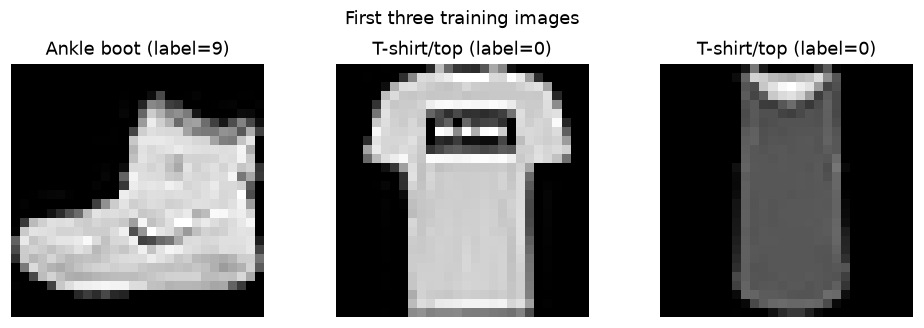

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, index in zip(axes, range(3)):
    ax.imshow(X_train[index], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{CLASS_NAMES[y_train[index]]} (label={y_train[index]})")
    ax.axis("off")
fig.suptitle("First three training images")
plt.tight_layout()
plt.show()

## 3. Get image features

Each image is a $28\times28$ grid of numbers between 0 and 1.

| Input type | What we do | Numbers per image |
|---|---|---:|
| Raw pixels | Put all pixels in one row | 784 |
| Block averages | Find the mean of each $4\times4$ block | 49 |
| Edge measurements | Use 49 means across columns and 49 across rows | 98 |
| Combined | Join block averages and edge measurements | 147 |

An edge is a change in pixel brightness. First, we find the absolute change
between pixels next to each other:

$$D_c[r,c]=|I[r,c+1]-I[r,c]|,\qquad
D_r[r,c]=|I[r+1,c]-I[r,c]|.$$

The first map is one column too small. We add a column of zeros on the right.
The second map is one row too small. We add a row of zeros at the bottom.
Both maps are now $28\times28$. A zero means that there is no next pixel.
We do not compare the last pixel with a new black pixel.
Then we find the mean of each $4\times4$ block in both maps.

In [4]:
def block_averages(images):
    images = np.asarray(images, dtype=float)
    if images.ndim != 3 or images.shape[1:] != (28, 28):
        raise ValueError("Expected an array with shape (N, 28, 28)")
    # Axes: image, block row, row inside a block,
    #      block column, column inside a block.
    return images.reshape(-1, 7, 4, 7, 4).mean(axis=(2, 4)).reshape(-1, 49)

def edge_maps(images):
    across_columns = np.abs(np.diff(images, axis=2))
    across_rows = np.abs(np.diff(images, axis=1))
    across_columns = np.pad(across_columns, ((0, 0), (0, 0), (0, 1)))
    across_rows = np.pad(across_rows, ((0, 0), (0, 1), (0, 0)))
    return across_columns, across_rows

def extract_features(images):
    images = np.asarray(images, dtype=float)
    blocks = block_averages(images)
    columns, rows = edge_maps(images)
    edges = np.concatenate([block_averages(columns), block_averages(rows)], axis=1)
    return {
        "Raw pixels": images.reshape(len(images), 784),
        "Block averages": blocks,
        "Edge measurements": edges,
        "Combined": np.concatenate([blocks, edges], axis=1),
    }

# Check block means and the direction of pixel changes.
probe = np.arange(784, dtype=float).reshape(1, 28, 28) / 783
manual_blocks = np.array([probe[0, r:r+4, c:c+4].mean()
                          for r in range(0, 28, 4) for c in range(0, 28, 4)])
np.testing.assert_allclose(block_averages(probe)[0], manual_blocks)
ramp = np.broadcast_to(np.arange(28) / 27, (1, 28, 28))
dx, dy = edge_maps(ramp)
np.testing.assert_allclose(dx[:, :, :-1], 1 / 27)
np.testing.assert_allclose(dx[:, :, -1], 0)
np.testing.assert_allclose(dy, 0)
np.testing.assert_allclose(extract_features(np.ones((1, 28, 28)))["Edge measurements"], 0)
print("Block mean, direction, and padding checks passed.")

Block mean, direction, and padding checks passed.


## 4. Make a noisy test copy

We add noise only to a copy of the test images.
The training images and the original test images stay clean.

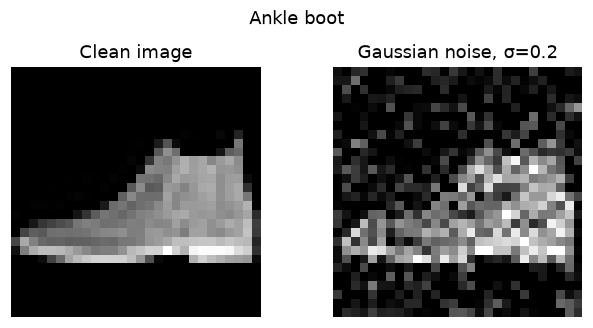

Seed=42; std=0.2; clipping=[0, 1]


In [5]:
# OUR CHOICE: use the starter notebook noise code here if it becomes available.
NOISE_SEED = 42
NOISE_STD = 0.2
rng = np.random.default_rng(NOISE_SEED)
noise = rng.normal(loc=0.0, scale=NOISE_STD, size=X_test.shape)
X_test_noisy = np.clip(X_test + noise, 0.0, 1.0)
assert not np.shares_memory(X_test, X_test_noisy)
assert 0 <= X_test_noisy.min() <= X_test_noisy.max() <= 1
np.testing.assert_array_equal(X_test, test_images[:1000].astype(float) / 255.0)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for ax, image, title in zip(axes, [X_test[0], X_test_noisy[0]],
                            ["Clean image", f"Gaussian noise, σ={NOISE_STD}"]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
fig.suptitle(CLASS_NAMES[y_test[0]])
plt.tight_layout()
plt.show()
print(f"Seed={NOISE_SEED}; std={NOISE_STD}; clipping=[0, 1]")

In [6]:
train_features = extract_features(X_train)
clean_features = extract_features(X_test)
noisy_features = extract_features(X_test_noisy)
expected_dimensions = {"Raw pixels": 784, "Block averages": 49,
                       "Edge measurements": 98, "Combined": 147}
shape_rows = []
for split, features, size in [("Train / clean", train_features, 6000),
                               ("Test / clean", clean_features, 1000),
                               ("Test / noisy", noisy_features, 1000)]:
    for name, values in features.items():
        assert values.shape == (size, expected_dimensions[name])
        assert np.isfinite(values).all()
        shape_rows.append({"Dataset": split, "Features": name, "Shape": str(values.shape)})
display(pd.DataFrame(shape_rows))

,Dataset,Features,Shape
0,Train / clean,Raw pixels,"(6000, 784)"
1,Train / clean,Block averages,"(6000, 49)"
2,Train / clean,Edge measurements,"(6000, 98)"
3,Train / clean,Combined,"(6000, 147)"
4,Test / clean,Raw pixels,"(1000, 784)"
5,Test / clean,Block averages,"(1000, 49)"
6,Test / clean,Edge measurements,"(1000, 98)"
7,Test / clean,Combined,"(1000, 147)"
8,Test / noisy,Raw pixels,"(1000, 784)"
9,Test / noisy,Block averages,"(1000, 49)"


## 5. Train two models

We use the exact model settings from the task:
`MLPClassifier(hidden_layer_sizes=(32,), max_iter=80, random_state=42)`.
All other settings keep their default values.

Each model uses `fit` only once, with clean training data.
We do not use test images for training or change the settings to get better scores.
We do not add extra scaling.

A model may need more than 80 steps to finish learning.
If this happens, we show the warning. We keep the limit at 80 because the
task asks for this value.

In [7]:
models = {}
training_rows = []
for name in ["Raw pixels", "Combined"]:
    model = MLPClassifier(hidden_layer_sizes=(32,), max_iter=80, random_state=42)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(train_features[name], y_train)
    for warning in caught:
        print(f"{name}: {warning.category.__name__}: {warning.message}")
    models[name] = model
    training_rows.append({"Model": name, "Steps": model.n_iter_,
                          "Final training loss": model.loss_})
display(pd.DataFrame(training_rows))

Raw pixels: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (80) reached and the optimization hasn't converged yet.


Combined: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (80) reached and the optimization hasn't converged yet.


,Model,Steps,Final training loss
0,Raw pixels,80,0.183042
1,Combined,80,0.352929


## 6. Four test results

We use the same trained raw model for clean and noisy raw features.
We use the same trained combined model for clean and noisy combined features.

$$Accuracy=\frac{N_{\mathrm{correct}}}{1000}.$$

For the last table column, we calculate:

$$\text{Change in percentage points}
=100(Accuracy_{\mathrm{noisy}}-Accuracy_{\mathrm{clean}}).$$

A negative number means that accuracy went down.
For example, a change from 80% to 70% is a change of −10 percentage points (pp).

In [8]:
evaluation_rows = []
summary_rows = []
for name, model in models.items():
    scores = {}
    for split, features in [("Clean", clean_features), ("Noisy", noisy_features)]:
        predicted = model.predict(features[name])
        correct = int(np.count_nonzero(predicted == y_test))
        accuracy = correct / len(y_test)
        scores[split] = accuracy
        evaluation_rows.append({"Model input": name, "Test set": split,
                                "Correct": correct, "Total": len(y_test),
                                "Accuracy": accuracy})
    summary_rows.append({"Model input": f"{name} {expected_dimensions[name]}",
                         "Clean test accuracy (%)": 100 * scores["Clean"],
                         "Noisy test accuracy (%)": 100 * scores["Noisy"],
                         "Noisy - clean (pp)": 100 * (scores["Noisy"] - scores["Clean"])})
evaluations = pd.DataFrame(evaluation_rows)
results = pd.DataFrame(summary_rows)
display(evaluations.round(4))
display(results.round(2))
assert len(evaluations) == 4 and evaluations["Total"].eq(1000).all()

,Model input,Test set,Correct,Total,Accuracy
0,Raw pixels,Clean,847,1000,0.847
1,Raw pixels,Noisy,763,1000,0.763
2,Combined,Clean,866,1000,0.866
3,Combined,Noisy,402,1000,0.402


,Model input,Clean test accuracy (%),Noisy test accuracy (%),Noisy - clean (pp)
0,Raw pixels 784,84.7,76.3,-8.4
1,Combined 147,86.6,40.2,-46.4


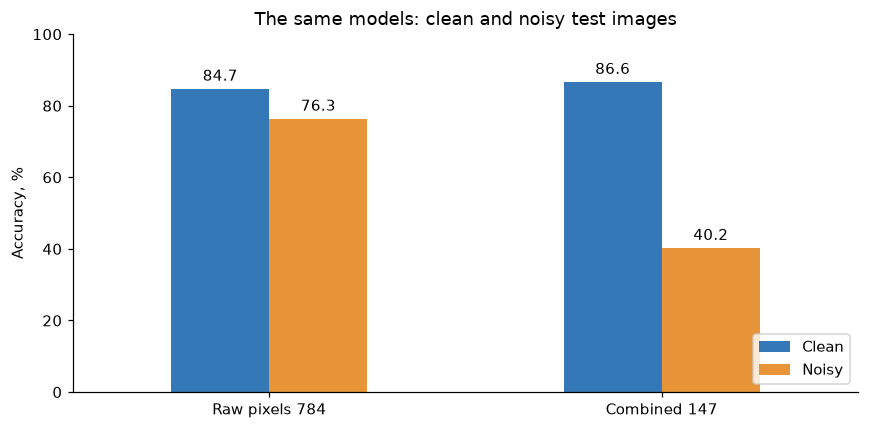

In [9]:
plot_data = results.set_index("Model input")[["Clean test accuracy (%)",
                                             "Noisy test accuracy (%)"]]
ax = plot_data.plot.bar(rot=0, figsize=(8, 4), color=["#3478b8", "#e79538"])
ax.set_ylabel("Accuracy, %")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.set_title("The same models: clean and noisy test images")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)
ax.legend(["Clean", "Noisy"], loc="lower right")
plt.tight_layout()
plt.show()

## 7. Answers

**What does block averaging lose?**

It keeps the mean brightness of a small area. It loses the exact position
of pixels inside that area. Small lines, details, and patterns can disappear.
Two different blocks can have the same mean.
Block averaging can reduce random noise, but it does not always give a better score.

**Why can noise affect edge measurements?**

Edge measurements use the difference between two nearby pixels.
Noise changes both pixels. It can make a false edge in an area with no real edge.
We use the absolute difference, so these false changes are positive.
Taking their mean does not remove all of them.

Before clipping, two independent noise values with variance $\sigma^2$
give a difference with variance $2\sigma^2$.
Here, variance describes how much the values change.
Clipping also changes the noise near pixel values 0 and 1.

**Which input is better on clean and noisy images?**

The next cell answers this question with our actual scores.

In [10]:
lines = []
for split, title in [("Clean", "Clean test set"),
                     ("Noisy", "Noisy test set")]:
    subset = evaluations[evaluations["Test set"] == split]
    details = "; ".join(
        f'{row["Model input"]}: **{row["Accuracy"]:.1%}** ({row["Correct"]}/1000)'
        for _, row in subset.iterrows())
    best = subset[subset["Accuracy"] == subset["Accuracy"].max()]["Model input"].tolist()
    conclusion = f'**{best[0]}** is better' if len(best) == 1 else "both scores are the same"
    lines.append(f"- **{title}:** {details}; {conclusion}.")
for _, row in results.iterrows():
    lines.append(f'- Change for {row["Model input"]}: '
                 f'**{row["Noisy - clean (pp)"]:+.1f} pp**')
display(Markdown("\n".join(lines)))

- **Clean test set:** Raw pixels: **84.7%** (847/1000); Combined: **86.6%** (866/1000); **Combined** is better.
- **Noisy test set:** Raw pixels: **76.3%** (763/1000); Combined: **40.2%** (402/1000); **Raw pixels** is better.
- Change for Raw pixels 784: **-8.4 pp**
- Change for Combined 147: **-46.4 pp**

## 8. Conclusion and limits

We compared two input types with the same MLP settings and the same data.
Combined uses 147 numbers for each image. Raw pixels uses 784 numbers.
This means combined uses about 5.33 times fewer input numbers.

Block averages keep the main brightness of each area but lose small details.
Edge features show changes in brightness. They also react to noise.

A good score on clean images does not always mean a good score on noisy images.
The noisy accuracy tells us how well a model works with noise.
The change in percentage points tells us how much its accuracy falls.

Our scores are for one fixed set of images and one noise level.
We cannot say that one input type is always better.
Software versions are shown at the start of the notebook.
The noise settings are our choice because the starter notebook was not available.
The other fixed settings come from P2.pdf.